## 선택: 학습 시작

① 맨 위 시작 셀 실행 → ② 문제 풀기 → ③ 맨 아래 종료 셀 실행 후 종료 입력 → ④ Ctrl+S로 노트북 저장 → ⑤ 이 대화에 다 풀었어라고 알려주기.

타이머 없이도 풀 수 있어요. KST 벽시계 시간은 쉬거나 노트북을 닫은 시간도 포함하고 저장·채팅 시각과 달라요. 모두 실행 중에는 종료를 입력하지 마세요.

**공통 타이머:** 교재 폴더 옆의 \_shared/study_timer.py 한 벌을 사용해요. 루트 physical-ai-lab 또는 이 교재 폴더에서 실행해 주세요. 기록은 이 교재의 .study_timer에만 남아요. 자세한 안내: [공통 타이머](../_shared/README.md).


In [ ]:
import stat as _stat
from pathlib import Path as _Path


def _load_shared_timer():
    # 교재 ID·날짜·노트북 이름은 제작 때 고정한 값이에요.
    _lesson_id = "day22-goal-distance"
    _lesson_date = "2026-11-10"
    _notebook_name = "day22.ipynb"

    def _safe(path, directory=False):
        if ".." in path.parts:
            raise RuntimeError("상위 폴더 경로는 사용하지 않아요.")
        for item in [*reversed(path.parents), path]:
            info = item.lstat()
            if (
                _stat.S_ISLNK(info.st_mode)
                or getattr(info, "st_file_attributes", 0) & 0x400
            ):
                raise RuntimeError("바로가기·junction·reparse 경로는 사용하지 않아요.")
        if directory and not _stat.S_ISDIR(info.st_mode):
            raise RuntimeError("예상한 폴더가 아니에요.")
        if not directory and not _stat.S_ISREG(info.st_mode):
            raise RuntimeError("예상한 일반 파일이 아니에요.")
        return path

    _cwd = _safe(_Path.cwd(), directory=True)
    _candidates = []
    for _folder in (_cwd, _cwd / _lesson_id):
        if _folder.name == _lesson_id and (_folder / _notebook_name).is_file():
            _safe(_folder, directory=True)
            _candidates.append(_safe(_folder / _notebook_name))
    if len(_candidates) != 1:
        raise RuntimeError("교재 폴더가 없거나 모호해요.")
    _notebook_path = _candidates[0]
    _shared_dir = _safe(_notebook_path.parent.parent / "_shared", directory=True)
    _helper = _safe(_shared_dir / "study_timer.py")
    # 검사한 파일을 메모리에서 로드해 __pycache__를 만들지 않아요.
    _before = _helper.lstat()
    _source = _helper.read_bytes()
    _after = _safe(_helper).lstat()
    _identity = lambda info: (info.st_dev, info.st_ino, info.st_mtime_ns, info.st_size)
    if _identity(_before) != _identity(_after):
        raise RuntimeError("읽는 동안 공통 도구 파일이 바뀌었어요.")
    _module = {"__name__": "physical_ai_shared_timer"}
    exec(compile(_source, str(_helper), "exec"), _module)
    return _module["create_timer"](
        _lesson_id, _lesson_date, _notebook_name, notebook_path=_notebook_path
    )


try:
    _study_timer = _load_shared_timer()
except (OSError, RuntimeError, SyntaxError):
    print(
        "타이머 경로를 확인하지 못했어요. 루트 또는 교재 폴더에서 열고 _shared 폴더를 함께 보관해 주세요. 기록은 바꾸지 않았어요."
    )
else:
    _study_timer.action("start")

# Day22 | 목표까지 남은 거리와 도착 판단


2026-11-10 · 헴의 Physical AI · 실제 약 60분 잠정 목표


Day21의 좌표 이동과 경로 그래프는 통과했어요. 그 도구를 재사용하고, 오늘은 목표와 현재 위치 사이의 차이를 계산해 도착 여부를 판단해요.


### 목표와 실제 활용


- 목표까지 남은 방향과 직선거리를 구하고, 허용오차를 바꾸어 판단을 비교해요.
- 가상 로봇의 목표점 도착 확인에 쓰는 연결이에요. 이동 명령을 자동 생성하거나 실제 로봇을 움직이지는 않아요.


### 실제 약 60분 사용법


- 0~5분: 새 개념 시작 확인 · 5~15분: 필요한 예제와 단위
- 15~30분: Q1 함수 구현 · 30~40분: Q2 조건 변경
- 40~50분: Q3 경로에 연결 · 50~57분: Q4 디버깅
- 57~60분: Q5 설명과 저장. 예상 시간은 보장이 아니며 막히면 그 부분부터 이어가요.


> 명목 60분 자료를 실제 약 20분에 풀었던 점을 반영해 적용·구현·변형·설명 실습을 늘렸어요. 같은 유형을 세 배 반복하거나 수료 속도를 보장한다는 뜻은 아니에요.


### 선택 타이머 사용 순서


① 맨 위 시작 셀 실행 → ② 문제 풀기 → ③ 맨 아래 종료 셀 실행 후 종료 입력 → ④ Ctrl+S로 노트북 저장 → ⑤ 이 대화에 다 풀었어라고 알려주기.


표시 시간은 KST 벽시계 시간이에요. 쉬거나 노트북을 닫은 시간도 포함하며 순수 집중 시간, 저장 시각, 채팅 발송 시각과 달라요. 모두 실행 중에는 종료를 입력하지 마세요.


> 기존 Python과 matplotlib를 사용해요. 추가 설치·유료 GPU·실물 장비가 필요 없어요. 자료 도착은 기상이나 즉시 공부 요청이 아니에요.


## 시작 확인 | 이미 아는 부분은 바로 실습으로


**확인 문제 안내**

확인 문제 0 · 선택 경로 확인 / 2~3분. 그림의 R은 현재 위치 (1,1)m, G는 목표 위치 (3,2)m예요. R에서 G로 남은 변화량을 구하려면 어느 위치에서 어느 위치를 빼야 할까요? 이유만 먼저 말해 보세요. 답할 곳: 바로 아래 시작 확인 답안 Markdown 셀.


![시작 확인 입력. 파랑은 현재 위치, 주황 별은 목표, 초록 화살표는 현재에서 목표 방향이에요.](assets/01-start-input.png)

그림: 시작 확인 입력. 파랑은 현재 위치, 주황 별은 목표, 초록 화살표는 현재에서 목표 방향이에요.


- 시작 확인 답안: 주황에서 파랑을 뺀다. 이유: 이동거리 찾게.
- 내 경로: 예제부터


설명할 수 있으면 Q1부터 구현하고 필요한 설명만 돌아와 읽어요. 낯설면 다음 예제부터 시작해요. 시작 확인은 별도 필수 제출이 아니고, 답이 없다는 이유로 숙달을 가정하지 않아요.


### 색과 기호의 약속


- 파랑 원 R·S·P: 현재 또는 관측 위치. 주황 별 G: 목표 위치.
- 초록 화살표: 시작에서 끝 방향. 보라 점선: 허용 범위 또는 비교 경로.
- 모든 그림의 x/y는 바닥 위치이고 단위는 m예요. O는 원점, +x는 오른쪽, +y는 위쪽이에요. 흑백에서도 모양과 라벨로 구분해요.


## 최소 개념 1 | 위치와 남은 변화량


쉬운 뜻: 어디에 있는가와 목표까지 어느 쪽으로 얼마나 더 가야 하는가를 나눠요. 생활 비유: 집 주소는 위치이고, 집에서 도서관까지 오른쪽·위쪽으로 몇 칸 가야 하는지가 변화량이에요. 실제 용어는 위치 벡터와 목표까지의 오차 벡터예요.


![예제 전용: 현재 R(-1,1)m, 목표 G(2,5)m. 아래 계산은 이 예제만의 풀이예요.](assets/02-worked-example.png)

그림: 예제 전용: 현재 R(-1,1)m, 목표 G(2,5)m. 아래 계산은 이 예제만의 풀이예요.


x 쪽 남은 양은 2−(-1)=3m, y 쪽 남은 양은 5−1=4m예요. 목표에서 현재를 빼어 (3,4)m를 얻어요. 음수 성분은 그 축의 양의 방향과 반대라는 뜻이며 거리가 음수라는 뜻은 아니에요.


In [ ]:
example_current = (-1, 1)  # 현재 바닥 위치 (x, y), 단위 m
example_goal = (2, 5)  # 목표 바닥 위치 (x, y), 단위 m
example_dx = example_goal[0] - example_current[0]
example_dy = example_goal[1] - example_current[1]
print(example_dx, example_dy)

3 4


### 변수 이름 읽기


- current_xy: 현재 위치 두 숫자 (x,y), 둘 다 m.
- goal_xy: 목표 위치 두 숫자 (x,y), 둘 다 m.
- dx_m, dy_m: 목표에서 현재를 뺀 x·y 변화량, 단위 m.
- 앞의 d는 변화량을 가리키는 이름이에요. x 위치 자체와 구별해요.


## 최소 개념 2 | 두 성분을 직선거리로


![예제 전용: 초록 선의 길이를 구해요. 꺾어서 간 실제 경로의 길이와는 구별해요.](assets/02-worked-example.png)

그림: 예제 전용: 초록 선의 길이를 구해요. 꺾어서 간 실제 경로의 길이와는 구별해요.


#### 쉬운 뜻: 오른쪽 3m, 위쪽 4m를 한 줄의 거리로 바꿔요. 생활 비유: 가로·세로 두 변을 가진 직각삼각형의 빗변이에요.

- 실제 용어는 `유클리드 거리`, 또는 `벡터의 크기`예요.


예제에서 3²+4²=25이고, 제곱해서 25가 되는 0 이상 수는 5예요. 그래서 직선거리는 5m예요. math.hypot(dx_m, dy_m)가 이 계산을 해 줘요. 두 성분을 더한 7m는 이 직선거리가 아니에요.


In [ ]:
import math  # Python 기본 도구. 설치하지 않아요.

example_distance_m = math.hypot(example_dx, example_dy)
print(example_distance_m)  # 예제 결과: 5.0 m

5.0


hypot는 음수 성분도 받아 0 이상의 길이로 바꿔요. 두 위치가 같으면 거리는 0이에요. 내부 계산에는 반올림 전 숫자를 사용하고, round는 출력할 때만 써요.


> 모든 좌표는 같은 지도·같은 원점·같은 m 단위라는 약속이에요. 서로 다른 지도나 카메라 좌표를 바로 빼는 문제는 오늘 범위가 아니에요.


## 최소 개념 3 | 정확히 같지 않아도 도착인가?


![예제 전용: G(2,2)m를 중심으로 반지름 0.75m를 허용 범위로 정했어요.](assets/03-tolerance-example.png)

그림: 예제 전용: G(2,2)m를 중심으로 반지름 0.75m를 허용 범위로 정했어요.


쉬운 뜻: 목표에 충분히 가까움의 기준을 붙여요. 생활 비유: 과녁의 한 점이 아니라 작은 원 안에 들어오면 성공으로 정하는 일이에요. 실제 용어는 도착 허용오차(tolerance)예요.


예제 R(2.6,2)m는 목표까지 0.6m예요. 0.75m 기준 안에 있어 도착으로 정해요. 오늘 규칙은 remaining_m <= tolerance_m이면 arrived=True예요. 경계와 같은 거리도 포함해요.


### 함수 입력과 결과의 약속


- remaining_m: 목표까지 직선거리, 단위 m.
- tolerance_m: 도착 허용오차, 단위 m. 0 이상의 유한한 수예요.
- arrived: 규칙의 결과 True/False. 위치나 속도가 아니에요.
- 입력 좌표는 유한한 숫자 두 개예요. 누락·NaN·다른 좌표계 검사는 필수 범위가 아니에요.


> 도착 판정은 위치를 갱신하거나 모터를 정지시키지 않아요. 이 허용오차는 가상 실습의 비교값이며 실제 장비의 안전 기준이 아니에요.


## 확인 문제 Q1 | 목표 상태 함수 직접 구현


**확인 문제 안내**

필수 / 약 15분. R(2,1)m와 G(5,3)m를 사용해 아래 두 함수를 완성하세요.

1. 먼저 x·y 남은 양과 직선거리 예상값을 손으로 적어요.
2. goal_gap은 (dx_m,dy_m) 튜플을, goal_report는 새 사전을 반환해요.

- 답할 곳: Q1 코드 셀과 Q1 답안 Markdown 셀.


![Q1 입력과 일치하는 그림. 계산한 성분·거리·도착 결과는 표시하지 않았어요.](assets/04-q1-input.png)

그림: Q1 입력과 일치하는 그림. 계산한 성분·거리·도착 결과는 표시하지 않았어요.


In [ ]:
import math


def goal_gap(current_xy, goal_xy):
    # 목표에서 현재를 빼어 (x 변화량, y 변화량)을 반환해요.
    dx = goal_xy[0] - current_xy[0]
    dy = goal_xy[1] - current_xy[1]
    return dx, dy


def goal_report(current_xy, goal_xy, tolerance_m):
    # goal_gap과 math.hypot를 사용하세요.
    # 새 dict의 key: "delta_xy", "remaining_m", "arrived"
    # delta_xy: 튜플 / remaining_m: 숫자 / arrived: bool
    dx, dy = goal_gap(current_xy, goal_xy)
    print("dx:", dx, "| dy:", dy)
    distance = math.hypot(dx, dy)
    print(distance)
    return {
        "delta_xy": (dx, dy),
        "remaining_m": math.hypot(dx, dy),
        "arrived": tolerance_m >= math.hypot(dx, dy),
    }


q1_current = (2, 1)
q1_goal = (5, 3)
print("Q1: goal_gap 작성")
print("Q1: goal_report 작성")
print(goal_report(q1_current, q1_goal, 0.5))
print(q1_current, q1_goal)  # 입력 보존 확인

Q1: goal_gap 작성
Q1: goal_report 작성
dx: 3 | dy: 2
3.605551275463989
{'delta_xy': (3, 2), 'remaining_m': 3.605551275463989, 'arrived': False}
(2, 1) (5, 3)


Q1 답안

- dx 3 m / dy 2 m
- 직선거리 예상 1.0 m.
- 실행 비교: 변화량은 예상과 같고, 직선거리는 예상한 1.0m와 달리 약 3.606m가 나왔다
- 목표−현재인 이유: 현재 위치에서 목표까지의 방향과 변화량을 구하기 위해서.
- 입력 보존 확인: 동일.


> 예제 도구를 다른 입력에 적용하는 문제예요. 반환 key 철자는 뒤의 제공 코드와 맞춰 주세요. 완성 정답 코드는 시도 후 검사 때 제공해요.


## 확인 문제 Q2 | 허용오차만 바꿔 비교


**확인 문제 안내**

필수 / 약 10분. G(4,3)m는 고정하고 P0~P4는 서로 독립적인 관측 위치예요. 허용오차 0.5m, 1.0m로 모두 평가하세요. 바뀐 위치 이름과 경계인 P2의 판단을 설명하세요. 답할 곳: 제공 호출 코드의 출력과 Q2 답안 Markdown 셀. Q1 함수는 그대로 재사용해요.


![Q2의 다섯 관측 위치. P3와 G는 같은 좌표이며 별도 라벨로 목표를 구분해요.](assets/05-q2-input.png)

그림: Q2의 다섯 관측 위치. P3와 G는 같은 좌표이며 별도 라벨로 목표를 구분해요.


In [ ]:
goal_xy = (4, 3)
observations = {
    "P0": (0, 0),
    "P1": (2, 1),
    "P2": (3.5, 3),
    "P3": (4, 3),
    "P4": (4.4, 3.4),
}
for tolerance_m in [0.5, 1.0]:
    print("tolerance_m =", tolerance_m)
    for name, current_xy in observations.items():
        report = goal_report(current_xy, goal_xy, tolerance_m)
        print("name::", name, round(report["remaining_m"], 3), report["arrived"])

tolerance_m = 0.5
dx: 4 | dy: 3
5.0
name:: P0 5.0 False
dx: 2 | dy: 2
2.8284271247461903
name:: P1 2.828 False
dx: 0.5 | dy: 0
0.5
name:: P2 0.5 True
dx: 0 | dy: 0
0.0
name:: P3 0.0 True
dx: -0.40000000000000036 | dy: -0.3999999999999999
0.5656854249492382
name:: P4 0.566 False
tolerance_m = 1.0
dx: 4 | dy: 3
5.0
name:: P0 5.0 False
dx: 2 | dy: 2
2.8284271247461903
name:: P1 2.828 False
dx: 0.5 | dy: 0
0.5
name:: P2 0.5 True
dx: 0 | dy: 0
0.0
name:: P3 0.0 True
dx: -0.40000000000000036 | dy: -0.3999999999999999
0.5656854249492382
name:: P4 0.566 True


Q2의 두 칸은 서로 다른 질문이야.

1. 판단이 바뀐 이름 / 전후 판단
   같은 위치에서 도착 기준을 0.5m에서 1.0m로 바꿨을 때, 결과가 달라진 위치를 찾는 거야.

- 허용오차 0.5: P2, P3
- 허용오차 1.0: P2, P3, P4

2. P2가 경계일 때 무슨 결과인지, 그 이유
   이 칸은 0.5m 기준일 때 P2를 묻는 거야. P2의 거리가 딱 0.5m라서 기준과 같지?

결과는 True야. 이번 규칙은 기준보다 가깝거나 같아도 도착으로 보기 때문이야.

내가 ‘전후 판단’이라고만 쓰지 말고, ‘기준을 0.5m에서 1.0m로 바꾸기 전과 후의 결과’라고 적었어야 했어.


> 같은 이름끼리 비교하세요. 경계 판단에는 반올림한 거리 대신 원래 remaining_m을 쓰세요.


## 확인 문제 Q3 | 이동 경로에 새 판단 연결


**확인 문제 안내**

필수 / 약 10분. 시작 S(-1,0)m, 목표 G(3,3)m, 순서대로 적용할 이동량은 (2,0), (0,2), (2,1)m예요. walk_positions는 통과한 이동 도구를 반복 사용한 제공 코드예요. 새 이동 함수를 다시 만들지 않아요. 답할 곳: 뒤의 Q3 코드·그래프·답안 셀.


![Q3 입력. 계산하지 않은 중간·최종 위치나 도착 판단은 그림에 표시하지 않았어요.](assets/06-route-input.png)

그림: Q3 입력. 계산하지 않은 중간·최종 위치나 도착 판단은 그림에 표시하지 않았어요.


In [ ]:
def move_xy(x_m, y_m, dx_m, dy_m):
    return (x_m + dx_m, y_m + dy_m)


def walk_positions(start_xy, moves_xy):
    positions = [start_xy]
    current_xy = start_xy
    for dx_m, dy_m in moves_xy:
        current_xy = move_xy(current_xy[0], current_xy[1], dx_m, dy_m)
        positions.append(current_xy)
    return positions


start_xy = (-1, 0)
route_goal = (3, 3)
moves_xy = [(2, 0), (0, 2), (2, 1)]
positions = walk_positions(start_xy, moves_xy)

## Q3 계속 | 새 함수를 기록마다 호출하기


![같은 Q3 입력. 각 이동량은 이 그림의 바닥 x/y 축 기준이고 단위는 m예요.](assets/06-route-input.png)

그림: 같은 Q3 입력. 각 이동량은 이 그림의 바닥 x/y 축 기준이고 단위는 m예요.


아래 반복에서 goal_report의 반환값을 reports에 한 개씩 추가하세요. 처음 위치부터 모든 이동 후 위치까지 차례로 평가하고, 처음 True가 된 step을 찾아요. 반복·목록 문법을 새로 시험하는 과제가 아니라 새 거리 함수를 경로에 연결하는 실습이에요.


In [ ]:
reports = []
for current_xy in positions:
    # TODO: goal_report(current_xy, route_goal, 0.5)의
    # 반환값을 reports에 한 개씩 추가하세요.
    report = goal_report(current_xy, route_goal, 0.5)
    reports.append(report)

for step, (xy, report) in enumerate(zip(positions, reports)):
    print(step, xy, round(report["remaining_m"], 3), report["arrived"])

dx: 4 | dy: 3
5.0
dx: 2 | dy: 3
3.605551275463989
dx: 2 | dy: 1
2.23606797749979
dx: 0 | dy: 0
0.0
0 (-1, 0) 5.0 False
1 (1, 0) 3.606 False
2 (1, 2) 2.236 False
3 (3, 3) 0.0 True


Q3 답안: 처음 True가 된 step 3

- 그때 위치 (3,3) m
- 남은 거리 0 m.
- 이동 후 위치로 다시 계산하는 이유: 로봇이 이동하면 목표까지 남은 거리가 달라지기 때문이다.


> 이 실험은 정해진 이동을 끝까지 적용한 경로 분석이에요. arrived를 보고 이동을 취소하거나 새 경로를 만드는 제어기가 아니에요.


## Q3 제공 그래프 | 새 도구의 결과와 함께 읽기


![같은 Q3 시작과 목표. 실행하면 실제로 계산한 경로가 추가돼요.](assets/06-route-input.png)

그림: 같은 Q3 시작과 목표. 실행하면 실제로 계산한 경로가 추가돼요.


아래는 제공 코드예요. 본인 Q3 판단 연결을 완성한 뒤 실행해요. 숫자는 이동 순서, 별은 목표, 점선 원은 허용 범위예요. 그래프 문법을 다시 완성하는 과제가 아니에요.


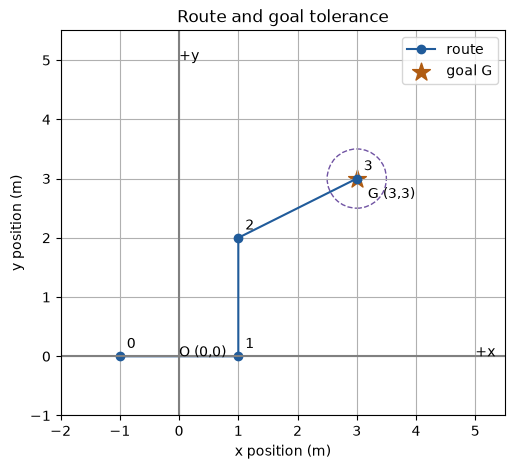

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(6, 5))
xs = [xy[0] for xy in positions]
ys = [xy[1] for xy in positions]
ax.plot(xs, ys, "o-", color="#205b9a", label="route")
ax.scatter(*route_goal, marker="*", s=180, color="#b05c12", label="goal G")
ax.add_patch(Circle(route_goal, 0.5, fill=False, color="#7053a3", linestyle="--"))
ax.axhline(0, color="gray")
ax.axvline(0, color="gray")
ax.set(
    xlabel="x position (m)", ylabel="y position (m)", title="Route and goal tolerance"
)
ax.annotate("O (0,0)", (0, 0))
ax.annotate("+x", (5, 0))
ax.annotate("+y", (0, 5))
for i, xy in enumerate(positions):
    ax.annotate(str(i), xy, xytext=(5, 6), textcoords="offset points")
ax.annotate("G (3,3)", route_goal, xytext=(8, -14), textcoords="offset points")
ax.set_xlim(-2, 5.5)
ax.set_ylim(-1, 5.5)
ax.set_aspect("equal")
ax.grid()
ax.legend()
plt.show()

## 확인 문제 Q4 | 원점에 속지 않는 거리


**확인 문제 안내**

필수 / 약 7분. 두 쌍의 위치는 같은 모양만큼 이동했어요. 아래 잘못된 함수에서 거리 계산 한 줄과 경계 비교 한 줄을 고치세요. 다른 기능을 추가하지 않아요. 두 쌍의 거리와 경계 입력을 먼저 예상하고 실행해 비교하세요. 답할 곳: Q4 코드 셀과 Q4 답안 Markdown 셀.


![Q4 입력: Ra(0,0)→Ga(3,4), Rb(10,0)→Gb(13,4). 같은 지도에서 비교해요.](assets/07-shift-input.png)

그림: Q4 입력: Ra(0,0)→Ga(3,4), Rb(10,0)→Gb(13,4). 같은 지도에서 비교해요.


In [ ]:
def debug_arrival(current_xy, goal_xy, tolerance_m):
    dx_m = goal_xy[0] - current_xy[0]
    dy_m = goal_xy[1] - current_xy[1]
    remaining_m = math.hypot(dx_m, dy_m)
    arrived = remaining_m <= tolerance_m
    return remaining_m, arrived


print(debug_arrival((0, 0), (3, 4), 0.5))
print(debug_arrival((10, 0), (13, 4), 0.5))
print(debug_arrival((1.5, 2), (2, 2), 0.5))

(5.0, False)
(5.0, False)
(0.5, True)


Q4 답안:

- 바꾼 거리 계산 줄 : 4
- 비교 줄 : 5
- 첫 두 입력의 거리 예상 5 m
- 실제 5
- 같은 모양인데 위치만 바꾼 실험이 오류를 찾는 데 도움이 되는 이유: 거리 계산 함수를 검증.


> 문제의 코드는 의도적으로 틀렸고 정상 함수의 답안 예시가 아니에요.


## Q4 경계와 Q5 | 숫자가 말해 주지 않는 것


![Q4 마지막 입력: R(1.5,2)m, G(2,2)m, 허용오차 0.5m. 실제 판단은 본인이 채워요.](assets/08-boundary-input.png)

그림: Q4 마지막 입력: R(1.5,2)m, G(2,2)m, 허용오차 0.5m. 실제 판단은 본인이 채워요.


In [ ]:
print(debug_arrival((1.5, 2), (2, 2), 0.5))

(0.5, True)


Q4 경계 답안:

- 마지막 입력의 예상 거리 0.25 m
- 도착 판단 TRUE
- 실행 결과 0.5
- 같아도 포함하는 규칙의 기호: <=.


![Q5 입력과 일치하는 환경. 회색 빗금은 벽, 초록 선은 두 위치의 직선 연결이에요.](assets/09-limit-input.png)

그림: Q5 입력과 일치하는 환경. 회색 빗금은 벽, 초록 선은 두 위치의 직선 연결이에요.


**확인 문제 안내**

확인 문제 Q5 · 필수

- 약 3분. 아래 R(0,1)m에서 G(4,1)m로 향하는 직선 사이에 벽이 있어요.

(1) remaining_m은 벽을 피해 실제로 걸어야 하는 길이인가요?

(2) arrived=True를 계산하면 위치나 모터가 자동으로 변하나요? 각각 한 문장으로 설명하세요.


Q5 답안: (1) ㄴㄴ. (2) 자동으로 변하진 않지

- 이 계산으로 아직 보장하지 못하는 것 한 가지: 한가지? 벽이있는지없는지 피할수있는지없는지 모르는거?.


## 선택 응용 | 남은 거리와 걸어온 길이


**확인 문제 안내**

확인 문제 Q6 · 선택. 더 해 보고 싶을 때만 해요. S(0,0)m에서 G(2,2)m까지 직선으로 가는 경우와 M(2,0)m를 거쳐 가는 경우를 비교하세요. 각 구간 길이를 hypot로 구해 더하고, 마지막 remaining_m과 총 이동 길이가 어떻게 다른지 설명하세요. 기대 결과: 두 경로의 길이와 마지막 남은 거리 비교. 답할 곳: 선택 Q6 코드·답안 셀. 안 해도 오늘 완료 가능해요.


![선택 Q6 입력. 초록은 직선 경로, 보라 점선은 M을 거치는 경로예요. 길이 정답은 표시하지 않았어요.](assets/10-optional-input.png)

그림: 선택 Q6 입력. 초록은 직선 경로, 보라 점선은 M을 거치는 경로예요. 길이 정답은 표시하지 않았어요.


선택 Q6 답안:

- 직선 경로 길이 2.8284271247461903m
- M 경유 길이 4 m
- 각 마지막 남은 거리 0 m
- 차이 설명: 경유하면 돌아감.


In [39]:
direct, goal = debug_arrival((0, 0), (2, 2), 0.5)
waypoint_1, goal1 = debug_arrival((0, 0), (2, 0), 0.5)
waypoint_2, goal2 = debug_arrival((2, 0), (2, 2), 0.5)

print(direct)
print(waypoint_1, waypoint_2)
print(waypoint_1 + waypoint_2)

2.8284271247461903
2.0 2.0
4.0


코드가 필요하면 아래 선택 코드 셀을 써요. 필수 문제를 마친 뒤 원할 때만 진행하고, 60분을 채우려고 추가 문제를 풀 필요는 없어요.


## 점검과 제출 | 오늘의 결과를 남기기


### 필수 제출과 완료 기준


- day22.ipynb에 Q1~Q4 함수·호출·저장 출력, Q3 그래프, Q1~Q5 설명을 남겨요.
- 목표−현재, 직선거리, 허용오차와 경계 포함 규칙이 코드·설명에서 확인되면 완료예요.
- 이미 코드와 출력이 근거이면 같은 답을 반복 작성하지 않아도 돼요. 막히면 해당 부분부터 이어가고 새 필수 과제를 쌓지 않아요.


짧은 회고: 실제 걸린 시간은 원할 때 알려 주세요. 막힌 부분이 없으면 없음이라고 적거나 그 칸을 비워도 괜찮아요. 타이머는 선택이에요.


### 오류를 찾는 순서


- 거리가 음수: dx/dy 성분과 길이를 혼동했는지 확인해요.
- 위치를 통째로 옮기니 거리도 달라짐: 목표 위치 자체의 크기를 계산했는지 확인해요.
- 경계에서만 다름: 비교 기호와 반올림 위치를 확인해요.
- None 출력: print만 했는지, 반환 key와 return이 있는지 확인해요.


### 타이머 보존과 다시 측정


시작 재실행·재시작은 기존 기록을 복원해요. 종료는 직접 종료를 입력할 때 최초 한 번 저장해요. 취소·손상·시간 역행은 기록을 바꾸지 않아요. 다시 측정하려면 선택 초기화 셀을 별도 활성화하고 초기화를 입력해 백업한 뒤 시작 셀을 다시 실행해요. 실제 기록은 실행할 때만 .study_timer에 생기고 공유 자료에는 넣지 않아요.


### 자료와 출처


PDF와 README.md는 같은 학습 내용이며 assets 그림을 함께 사용해요. 정답 공개는 사용자 시도 후예요. 개인 맞춤 자료이고 KANT 공식 교재가 아니에요. 공식 종일 부트캠프 주차를 개인 기간으로 환산하지 않아요.


기준 과정: https://kant-ai-campus.com/ai-physical
Python math.hypot: https://docs.python.org/3.12/library/math.html#math.hypot
2026-11-10 확인. Day21 실제 풀이·검증과 사용자 분량 조정 요청을 반영했어요.


## 선택: 짧은 회고

- 실제 걸린 시간(선택): \_\_\_
- 막힌 부분(없으면 비워도 됨): \_\_\_


## 선택: 새로 측정하기

정말 다시 잴 때만 아래 enabled=False를 True로 바꾸고 실행한 뒤 초기화를 입력하세요. 고유한 백업을 만든 뒤 시작 셀을 다시 실행해요.


In [ ]:
import stat as _stat
from pathlib import Path as _Path


def _load_shared_timer():
    # 교재 ID·날짜·노트북 이름은 제작 때 고정한 값이에요.
    _lesson_id = "day22-goal-distance"
    _lesson_date = "2026-11-10"
    _notebook_name = "day22.ipynb"

    def _safe(path, directory=False):
        if ".." in path.parts:
            raise RuntimeError("상위 폴더 경로는 사용하지 않아요.")
        for item in [*reversed(path.parents), path]:
            info = item.lstat()
            if (
                _stat.S_ISLNK(info.st_mode)
                or getattr(info, "st_file_attributes", 0) & 0x400
            ):
                raise RuntimeError("바로가기·junction·reparse 경로는 사용하지 않아요.")
        if directory and not _stat.S_ISDIR(info.st_mode):
            raise RuntimeError("예상한 폴더가 아니에요.")
        if not directory and not _stat.S_ISREG(info.st_mode):
            raise RuntimeError("예상한 일반 파일이 아니에요.")
        return path

    _cwd = _safe(_Path.cwd(), directory=True)
    _candidates = []
    for _folder in (_cwd, _cwd / _lesson_id):
        if _folder.name == _lesson_id and (_folder / _notebook_name).is_file():
            _safe(_folder, directory=True)
            _candidates.append(_safe(_folder / _notebook_name))
    if len(_candidates) != 1:
        raise RuntimeError("교재 폴더가 없거나 모호해요.")
    _notebook_path = _candidates[0]
    _shared_dir = _safe(_notebook_path.parent.parent / "_shared", directory=True)
    _helper = _safe(_shared_dir / "study_timer.py")
    # 검사한 파일을 메모리에서 로드해 __pycache__를 만들지 않아요.
    _before = _helper.lstat()
    _source = _helper.read_bytes()
    _after = _safe(_helper).lstat()
    _identity = lambda info: (info.st_dev, info.st_ino, info.st_mtime_ns, info.st_size)
    if _identity(_before) != _identity(_after):
        raise RuntimeError("읽는 동안 공통 도구 파일이 바뀌었어요.")
    _module = {"__name__": "physical_ai_shared_timer"}
    exec(compile(_source, str(_helper), "exec"), _module)
    return _module["create_timer"](
        _lesson_id, _lesson_date, _notebook_name, notebook_path=_notebook_path
    )


try:
    _study_timer = _load_shared_timer()
except (OSError, RuntimeError, SyntaxError):
    print(
        "타이머 경로를 확인하지 못했어요. 루트 또는 교재 폴더에서 열고 _shared 폴더를 함께 보관해 주세요. 기록은 바꾸지 않았어요."
    )
else:
    enabled = True  # 정말 다시 잴 때만 True로 바꾸세요.
    if enabled:
        _study_timer.action("reset", input("초기화하려면 초기화 입력: "), enabled=True)
    else:
        print("초기화는 비활성화되어 있어요.")

## 선택: 학습 종료

완료했을 때만 아래 셀을 실행하고 종료를 입력하세요. 빈 입력은 취소예요. 모두 실행 중에는 입력하지 마세요. 종료 뒤 Ctrl+S로 저장하고 이 대화에 알려 주세요.


In [ ]:
import stat as _stat
from pathlib import Path as _Path


def _load_shared_timer():
    # 교재 ID·날짜·노트북 이름은 제작 때 고정한 값이에요.
    _lesson_id = "day22-goal-distance"
    _lesson_date = "2026-11-10"
    _notebook_name = "day22.ipynb"

    def _safe(path, directory=False):
        if ".." in path.parts:
            raise RuntimeError("상위 폴더 경로는 사용하지 않아요.")
        for item in [*reversed(path.parents), path]:
            info = item.lstat()
            if (
                _stat.S_ISLNK(info.st_mode)
                or getattr(info, "st_file_attributes", 0) & 0x400
            ):
                raise RuntimeError("바로가기·junction·reparse 경로는 사용하지 않아요.")
        if directory and not _stat.S_ISDIR(info.st_mode):
            raise RuntimeError("예상한 폴더가 아니에요.")
        if not directory and not _stat.S_ISREG(info.st_mode):
            raise RuntimeError("예상한 일반 파일이 아니에요.")
        return path

    _cwd = _safe(_Path.cwd(), directory=True)
    _candidates = []
    for _folder in (_cwd, _cwd / _lesson_id):
        if _folder.name == _lesson_id and (_folder / _notebook_name).is_file():
            _safe(_folder, directory=True)
            _candidates.append(_safe(_folder / _notebook_name))
    if len(_candidates) != 1:
        raise RuntimeError("교재 폴더가 없거나 모호해요.")
    _notebook_path = _candidates[0]
    _shared_dir = _safe(_notebook_path.parent.parent / "_shared", directory=True)
    _helper = _safe(_shared_dir / "study_timer.py")
    # 검사한 파일을 메모리에서 로드해 __pycache__를 만들지 않아요.
    _before = _helper.lstat()
    _source = _helper.read_bytes()
    _after = _safe(_helper).lstat()
    _identity = lambda info: (info.st_dev, info.st_ino, info.st_mtime_ns, info.st_size)
    if _identity(_before) != _identity(_after):
        raise RuntimeError("읽는 동안 공통 도구 파일이 바뀌었어요.")
    _module = {"__name__": "physical_ai_shared_timer"}
    exec(compile(_source, str(_helper), "exec"), _module)
    return _module["create_timer"](
        _lesson_id, _lesson_date, _notebook_name, notebook_path=_notebook_path
    )


try:
    _study_timer = _load_shared_timer()
except (OSError, RuntimeError, SyntaxError):
    print(
        "타이머 경로를 확인하지 못했어요. 루트 또는 교재 폴더에서 열고 _shared 폴더를 함께 보관해 주세요. 기록은 바꾸지 않았어요."
    )
else:
    _study_timer.finish_interactive()